# 06 · Final pipeline

Two parts, kept separate so that their effects can be told apart:

- **A. Data and inference strategies** with a *fixed* trained model: NMS threshold, test-time augmentation, sliced inference, ensembling (WBF).
- **B. Model / training-data changes** with a *fixed* inference setting: more training frames, full augmentation, longer training.

Finally the chosen configuration is retrained on **all** labelled clips and used for the test submission.

## 1. Setup

In [1]:
import os, sys, json, shutil, glob
from pathlib import Path

REPO = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path("..").resolve()
if Path("/kaggle").exists() and not REPO.exists():
    !git clone https://github.com/dd8ria/ai-hw2.git {REPO}
    !pip install -q faster-coco-eval ultralytics==8.3.*
sys.path.insert(0, str(REPO / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as patches, cv2
import vdet, parallel, ultra, infer
from vdet import CLASSES

vdet.seed_everything()
ROOT = vdet.find_data_root()
OUT = Path("/kaggle/working") if Path("/kaggle").exists() else REPO / "outputs"
RUNS = OUT / "runs"; RUNS.mkdir(parents=True, exist_ok=True)
RESULT_DIRS = [RUNS, REPO / "results"]   # own runs + runs committed by the teammate
P = vdet.PROTOCOL

# restore finished runs from attached notebook outputs (any folder depth)
for cfg_file in glob.glob("/kaggle/input/**/runs/*/config.json", recursive=True):
    src = Path(cfg_file).parent
    if not (RUNS / src.name).exists():
        shutil.copytree(src, RUNS / src.name); print("restored", src.name)

Cloning into '/kaggle/working/repo'...
remote: Enumerating objects: 112, done.
remote: Counting objects: 100% (112/112), done.
remote: Compressing objects: 100% (103/103), done.
remote: Total 112 (delta 30), reused 22 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (112/112), 16.05 MiB | 19.93 MiB/s, done.
Resolving deltas: 100% (30/30), done.
restored final_b1_step5
restored final_b3_24ep
restored yolo_y0_base
restored yolo_y1_p2
restored yolo_y2_imgsz1024
restored yolo_y2_imgsz1536
restored yolo_y3_tal13


In [2]:
imgs, anns = vdet.load_all(ROOT)
folds = pd.read_csv(OUT / "folds.csv") if (OUT / "folds.csv").exists() else vdet.make_folds(imgs, P["n_folds"])
folds.to_csv(OUT / "folds.csv", index=False)   # the parallel runner reads the split from this file
train_frames, val_frames = vdet.protocol_frames(imgs, folds, P)
train_gt = anns[anns.key.isin(train_frames.key) & (anns.iscrowd == 0)]
print(json.dumps(P))
print(f"train: {len(train_frames)} frames | val: {len(val_frames)} frames / {val_frames.clip_uid.nunique()} clips")

COLS = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_max", "ms_per_img", "epochs"]
def show(res, cols=COLS):
    cols = [c for c in cols if c in res]
    num = [c for c in cols if c not in ("ms_per_img", "epochs")]
    return res[cols].style.format("{:.4f}", subset=num).format("{:.1f}", subset=[c for c in ["ms_per_img"] if c in cols])

{"val_fold": 0, "n_folds": 5, "step": 10, "val_step": 10, "imgsz": 1280, "epochs": 12, "seed": 42}
train: 2189 frames | val: 545 frames / 12 clips


,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_max,ms_per_img,epochs
run,,,,,,,,,
frcnn_e1_proposals,0.2561,0.4795,0.2441,0.1094,0.2032,0.4448,0.3902,114.3,12
yolo_y2_imgsz1536,0.2097,0.4052,0.1939,0.0926,0.1766,0.3248,0.3199,30.5,12
final_b1_step5,0.1925,0.3464,0.1867,0.0715,0.1518,0.3196,0.2765,24.2,12


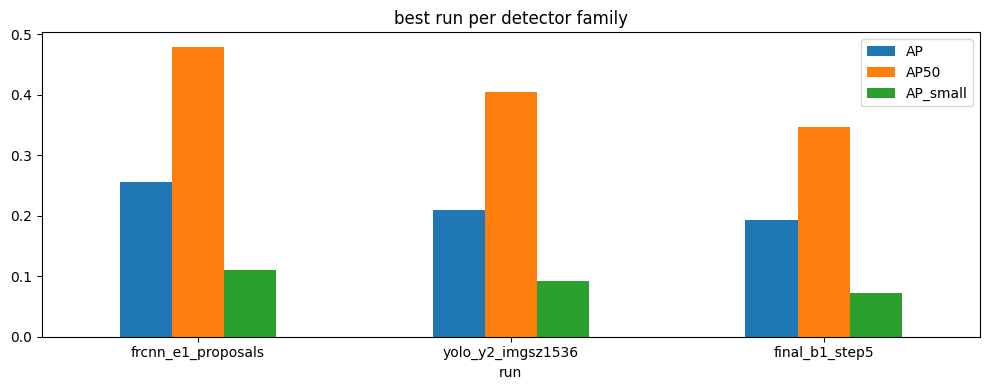

In [3]:
# All model results so far (own runs + teammate's committed results/)
allres = vdet.collect_results(RESULT_DIRS)
if len(allres):
    allres["family"] = allres.index.str.split("_").str[0]
    best = allres.loc[allres.groupby("family").AP.idxmax()].sort_values("AP", ascending=False)
    display(show(best))
    best[["AP", "AP50", "AP_small"]].plot.bar(figsize=(10, 4), rot=0, title="best run per detector family")
    plt.tight_layout(); plt.savefig(OUT / "summary_all_models.png", dpi=120); plt.show()

## 2. Part A — inference strategies on a fixed model

In [4]:
# The best single model. Its run folder must be available: own RUNS, or attach the teammate's
# Kaggle notebook output as input (the setup cell copies */runs/* automatically).
BASE_RUN = "yolo_y0_base"
cfg = json.loads((RUNS / BASE_RUN / "config.json").read_text()); IMGSZ = cfg["imgsz"]
model = ultra.load(RUNS / BASE_RUN)
A = {}
def evalA(name, preds):
    A[name] = vdet.coco_evaluate(val_frames, anns, preds, per_class=False); print(name, {k: round(v, 4) for k, v in A[name].items()})
    return preds

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## 3. Part B — training data / model changes with fixed inference

In [5]:
# B1: denser frame sampling (step 5 instead of 10); B2: full Ultralytics augmentation (mosaic, scale, HSV);
# B3: longer training. All on the BASE_RUN architecture, evaluated with plain inference.
data5 = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_fold0_step5",
                                step=5, val_step=P["val_step"])
data10 = OUT / "yolo_fold0" / "data.yaml"
if not data10.exists():
    data10 = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_fold0",
                                     step=P["step"], val_step=P["val_step"])
FULL_AUG = dict(mosaic=1.0, scale=0.5, translate=0.1, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, close_mosaic=3)
B = {"final_b1_step5": (data5, {**cfg}),
     "final_b2_fullaug": (data10, {**cfg, "aug": FULL_AUG}),
     "final_b3_24ep": (data10, {**cfg, "epochs": 2 * cfg["epochs"]})}
RUN_B = ["final_b1_step5", "final_b2_fullaug", "final_b3_24ep"]
# each job carries its own dataset; with 2 GPUs b1 + b2 run together, then b3
parallel.run_parallel([(n, B[n][1], B[n][0]) for n in RUN_B], RUNS, folds_csv=OUT / "folds.csv")
display(show(pd.concat([vdet.collect_results(RESULT_DIRS, BASE_RUN), vdet.collect_results(RESULT_DIRS, "final_b")])))

train:   4353 frames,  3119 masked copies
val  :    545 frames,   409 masked copies
train:   2189 frames,  1570 masked copies
val  :    545 frames,   409 masked copies
final_b1_step5: already finished, skipped
final_b3_24ep: already finished, skipped
1 jobs on GPUs [0, 1]
[   0.0 min] started final_b2_fullaug on GPU 0
[   0.5 min] final_b2_fullaug (GPU 0): train: Scanning /kaggle/working/yolo_fold0/labels/train/train__uav0000013_00000_v... 810 images, 0 backgrounds, 0 corrupt: 37% ━━━━──────── 810/2189 524.3it/s 1.7s<2.6s
[  10.5 min] final_b2_fullaug (GPU 0):        4/12      12.4G      1.504     0.9368       1.08        495       1280: 71% ━━━━━━━━╸─── 195/274 1.8it/s 1:48<43.6s
[  20.5 min] final_b2_fullaug (GPU 0):        8/12      13.2G      1.408     0.7859      1.035        464       1280: 41% ━━━━╸─────── 113/274 1.8it/s 1:03<1:29
[  30.5 min] final_b2_fullaug (GPU 0):       12/12      8.01G      1.324     0.6934      1.029        252       1280: 26% ━━━───────── 72/274 1.9it/s

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_max,ms_per_img,epochs
run,,,,,,,,,
yolo_y0_base,0.2028,0.3653,0.1958,0.0959,0.1533,0.3495,0.3058,23.3,12
final_b1_step5,0.1925,0.3464,0.1867,0.0715,0.1518,0.3196,0.2765,24.2,12
final_b2_fullaug,0.2366,0.4288,0.2264,0.1150,0.1773,0.3953,0.3514,17.5,12
final_b3_24ep,0.1921,0.3480,0.1844,0.0925,0.1413,0.3325,0.2783,19.1,24


## 4. Final model: chosen settings, trained on all labelled clips

In [6]:
# Results for the repo: unzip results.zip from the notebook Output into <repo>/results/ and commit.
vdet.export_results(RUNS, OUT / "results", preds_for=("final_all_clips",))

results archive: /kaggle/working/results.zip


PosixPath('/kaggle/working/results.zip')